In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/mydata")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

for folder_name in ["Dresses", "mixed", "tshirt", "women fashion"]:
    folder = DATASET_DIR / folder_name

    try:
        count = 0

        for path in folder.iterdir():
            try:
                if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                    count += 1
            except OSError:
                continue

        print(f"{folder_name}: {count} images")

    except OSError as error:
        print(f"{folder_name}: FAILED — {error}")

Dresses: 464 images
mixed: 44441 images
tshirt: 1993 images
women fashion: 96 images


In [4]:
import csv
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/mydata")
MANIFEST_PATH = Path("/content/drive/MyDrive/image_manifest.csv")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

with MANIFEST_PATH.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["image_id", "category", "drive_path"]
    )
    writer.writeheader()

    image_id = 0

    for category in ["Dresses", "mixed", "tshirt", "women fashion"]:
        folder = DATASET_DIR / category

        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                writer.writerow({
                    "image_id": image_id,
                    "category": category,
                    "drive_path": str(path)
                })
                image_id += 1

print("Manifest saved:", MANIFEST_PATH)
print("Images recorded:", image_id)

Manifest saved: /content/drive/MyDrive/image_manifest.csv
Images recorded: 46994


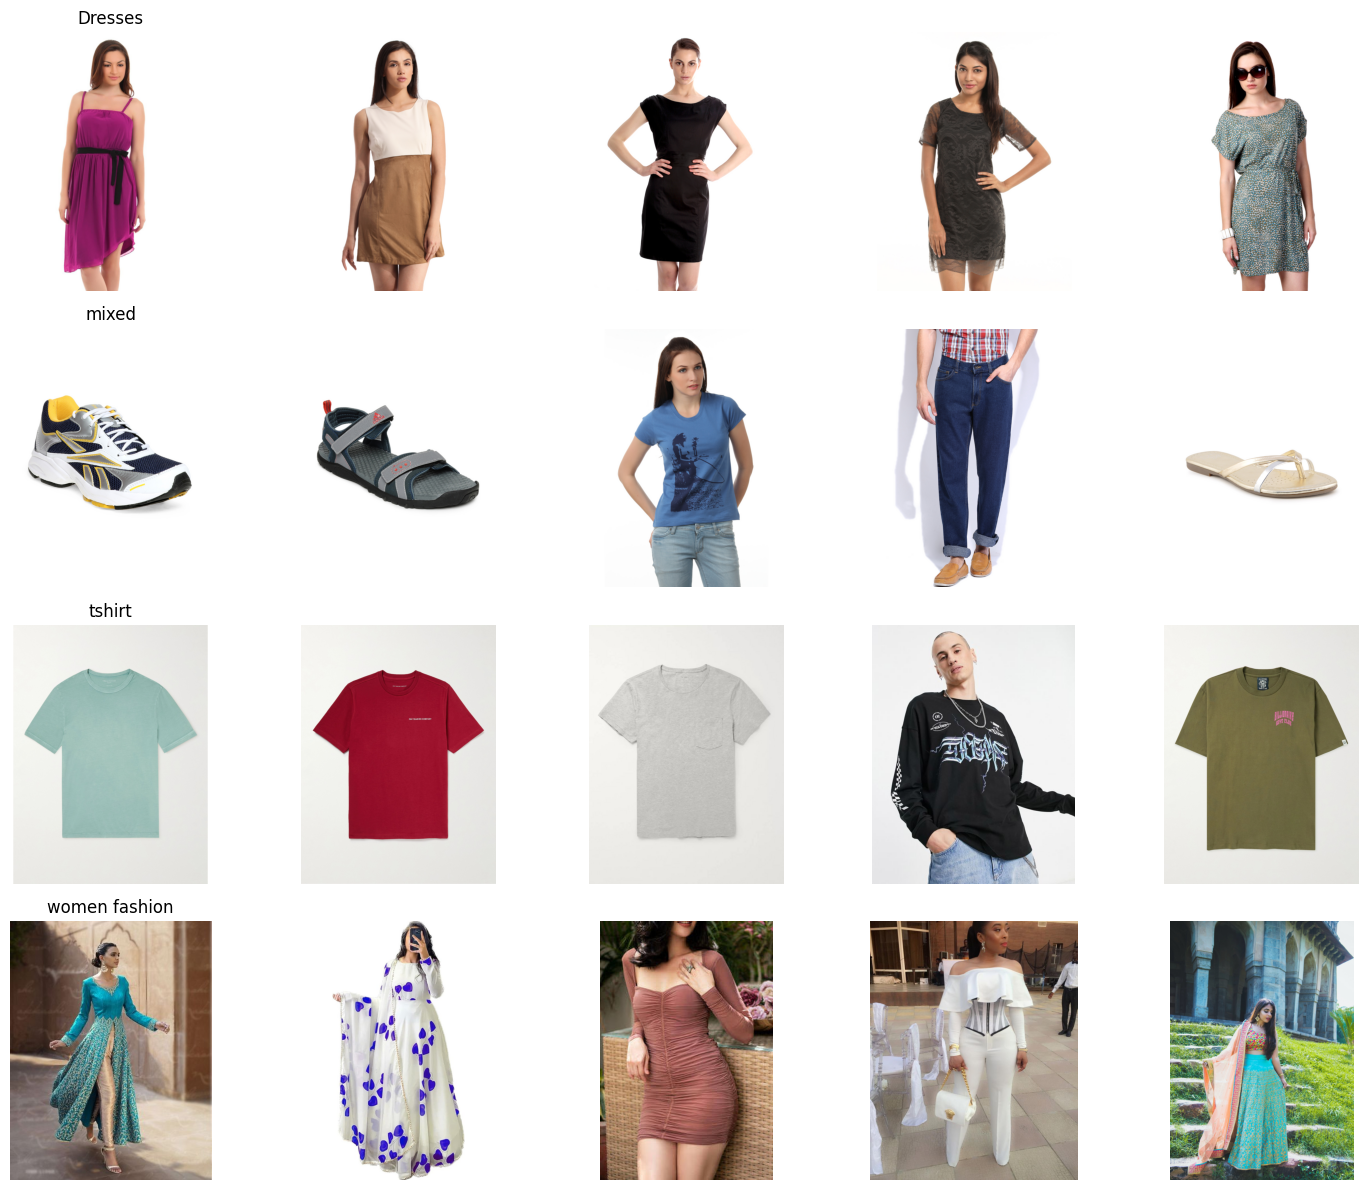

In [5]:
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_DIR = Path("/content/drive/MyDrive/mydata")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

random.seed(42)

categories = ["Dresses", "mixed", "tshirt", "women fashion"]

fig, axes = plt.subplots(
    len(categories), 5,
    figsize=(15, 12)
)

for row, category in enumerate(categories):
    folder = DATASET_DIR / category

    paths = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(paths, min(5, len(paths)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col >= len(samples):
            continue

        try:
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(category if col == 0 else "")
        except Exception as e:
            ax.set_title(f"Read error: {str(e)[:20]}")

plt.tight_layout()
plt.show()

In [6]:
%pip install -q faiss-cpu

In [7]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Remove the classification layer to obtain 2048-dimensional features.
model.fc = nn.Identity()
model = model.to(device)
model.eval()

preprocess = weights.transforms()

print("Device:", device)
print("Embedding dimension: 2048")

Device: cuda
Embedding dimension: 2048


In [8]:
from pathlib import Path
import numpy as np
from tqdm.auto import tqdm

DATASET_DIR = Path("/content/drive/MyDrive/mydata")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

image_paths = []

for category in ["Dresses", "mixed", "tshirt", "women fashion"]:
    folder = DATASET_DIR / category
    image_paths.extend(
        p for p in sorted(folder.iterdir())
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

image_paths = image_paths[:100]

embeddings = []
valid_paths = []

with torch.inference_mode():
    for path in tqdm(image_paths):
        try:
            with Image.open(path) as img:
                image = preprocess(img.convert("RGB")).unsqueeze(0).to(device)

            vector = model(image)
            vector = torch.nn.functional.normalize(vector, p=2, dim=1)

            embeddings.append(vector.cpu().numpy()[0])
            valid_paths.append(str(path))

        except Exception as error:
            print(f"Skipped {path.name}: {error}")

embeddings = np.asarray(embeddings, dtype=np.float32)

print("Valid images:", len(valid_paths))
print("Embedding matrix:", embeddings.shape)

  0%|          | 0/100 [00:00<?, ?it/s]

Valid images: 100
Embedding matrix: (100, 2048)


In [9]:
import faiss

index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)

print("Indexed vectors:", index.ntotal)

Indexed vectors: 100


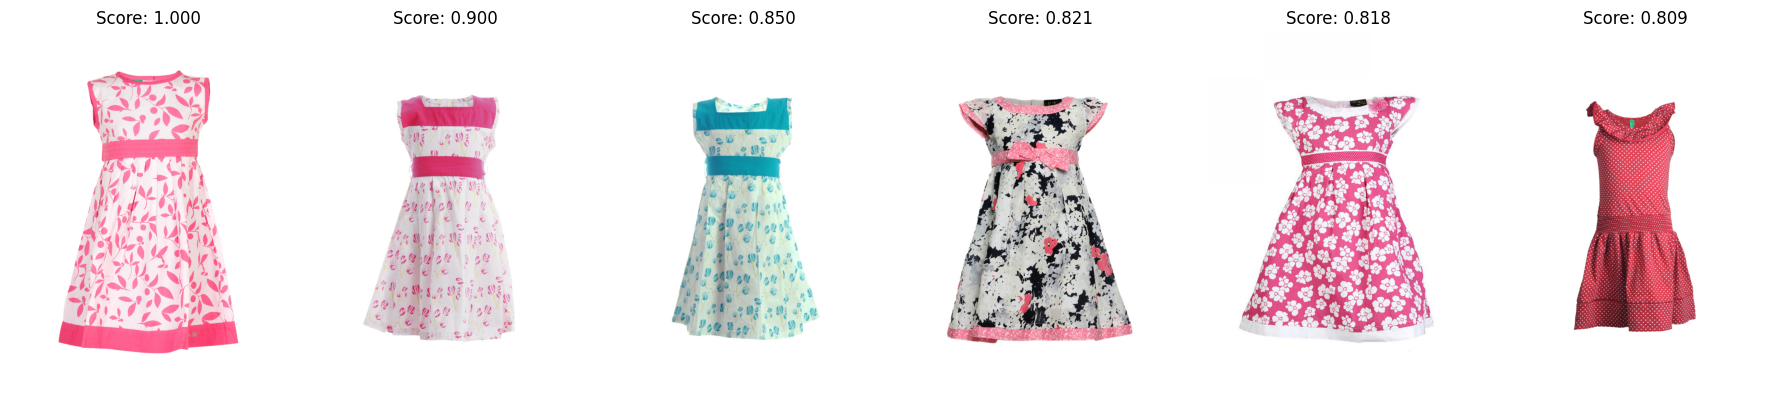

In [10]:
import matplotlib.pyplot as plt

query_idx = 0
query_vector = embeddings[query_idx:query_idx + 1]

scores, indices = index.search(query_vector, 6)

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for ax, idx, score in zip(axes, indices[0], scores[0]):
    ax.axis("off")

    if idx < 0:
        continue

    with Image.open(valid_paths[idx]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"Score: {score:.3f}")

plt.tight_layout()
plt.show()

In [11]:
import torch
import numpy as np
from PIL import Image

def extract_embedding(image_path):
    with Image.open(image_path) as image:
        image = preprocess(image.convert("RGB")).unsqueeze(0).to(device)

    with torch.inference_mode():
        embedding = model(image)
        embedding = torch.nn.functional.normalize(
            embedding, p=2, dim=1
        )

    return embedding.cpu().numpy()[0].astype(np.float32)

In [12]:
from pathlib import Path
import time

image_paths = [
    Path(p) for p in valid_paths[:32]
]

start = time.time()
test_embeddings = []

for path in image_paths:
    try:
        test_embeddings.append(extract_embedding(path))
    except Exception as error:
        print(f"Skipped {path.name}: {error}")

print("Successful embeddings:", len(test_embeddings))
print("Elapsed seconds:", round(time.time() - start, 2))

Successful embeddings: 32
Elapsed seconds: 2.26


In [13]:
import time
import torch
import numpy as np
from PIL import Image

def extract_batch(paths):
    tensors = []
    valid_paths = []

    for path in paths:
        try:
            with Image.open(path) as image:
                tensor = preprocess(image.convert("RGB"))
            tensors.append(tensor)
            valid_paths.append(str(path))
        except Exception as error:
            print(f"Skipped {path.name}: {error}")

    if not tensors:
        return np.empty((0, 2048), dtype=np.float32), []

    batch = torch.stack(tensors).to(device)

    with torch.inference_mode():
        vectors = model(batch)
        vectors = torch.nn.functional.normalize(vectors, p=2, dim=1)

    return vectors.cpu().numpy().astype(np.float32), valid_paths


start = time.time()

batch_embeddings, batch_paths = extract_batch(image_paths[:32])

if device.type == "cuda":
    torch.cuda.synchronize()

print("Successful embeddings:", len(batch_paths))
print("Embedding shape:", batch_embeddings.shape)
print("Elapsed seconds:", round(time.time() - start, 2))

Successful embeddings: 32
Embedding shape: (32, 2048)
Elapsed seconds: 1.85


In [14]:
import json
import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/image_manifest.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/image_similarity_artifacts/embedding_chunks"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 32
CHUNK_SIZE = 500

manifest = pd.read_csv(MANIFEST_PATH)

required = {"image_id", "category", "drive_path"}
assert required.issubset(manifest.columns), (
    f"Missing columns: {required - set(manifest.columns)}"
)

assert len(manifest) == 46994, (
    f"Expected 46994 rows, found {len(manifest)}"
)

print("Images in manifest:", len(manifest))
print("Device:", device)
print("Output directory:", OUTPUT_DIR)

Images in manifest: 46994
Device: cuda
Output directory: /content/drive/MyDrive/image_similarity_artifacts/embedding_chunks


In [15]:

import os
import json
import time
import numpy as np
import torch

from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

# Assumes these already exist:
# model, preprocess, device, manifest, CHUNK_SIZE, OUTPUT_DIR

BATCH_SIZE = 128
IO_THREADS = 32


OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.backends.cudnn.benchmark = True
torch.set_num_threads(2)

use_cuda = device.type == "cuda"
model = model.eval().to(device).to(memory_format=torch.channels_last)
if use_cuda:
    model = model.half()

paths = manifest["drive_path"].astype(str).tolist()
ids = manifest["image_id"].to_numpy()
total = len(paths)
num_chunks = (total + CHUNK_SIZE - 1) // CHUNK_SIZE


def valid_chunk(c):
    """Validate chunk shape and mapping before skipping it."""
    p = OUTPUT_DIR / f"chunk_{c:04d}.npz"
    a = c * CHUNK_SIZE
    b = min(a + CHUNK_SIZE, total)
    expected_ids = ids[a:b].astype(np.int64)
    expected_paths = np.asarray(paths[a:b], dtype=str)

    if not p.exists():
        return False

    try:
        with np.load(p, allow_pickle=False) as z:
            emb = z["embeddings"]
            saved_ids = z["image_ids"]
            saved_paths = z["image_paths"]

            return (
                emb.ndim == 2
                and emb.shape[1] == 2048
                and len(emb) == b - a
                and np.isfinite(emb).all()
                and np.array_equal(saved_ids, expected_ids)
                and np.array_equal(saved_paths.astype(str), expected_paths)
            )
    except Exception:
        return False


pending = [c for c in range(num_chunks) if not valid_chunk(c)]
print(f"{len(pending)}/{num_chunks} chunks pending")

def load_one(r):
    try:
        with Image.open(paths[r]) as im:
            # Keep preprocessing consistent with the pretrained weights.
            tensor = preprocess(im.convert("RGB"))
        return r, tensor, None
    except Exception as e:
        return r, None, str(e)[:250]


error_file = OUTPUT_DIR / "errors.jsonl"
started = time.time()

with ThreadPoolExecutor(max_workers=IO_THREADS) as pool:
    for c in pending:
        # Do not overwrite a valid chunk if another run created it.
        if valid_chunk(c):
            print(f"Skipping chunk {c + 1}: already valid")
            continue

        a = c * CHUNK_SIZE
        b = min(a + CHUNK_SIZE, total)
        vectors = []
        successful_rows = []
        chunk_errors = []

        print(f"\nProcessing chunk {c + 1}/{num_chunks}")

        for start in tqdm(range(a, b, BATCH_SIZE), leave=False):
            stop = min(start + BATCH_SIZE, b)

            # map preserves row order and limits outstanding work to this batch.
            results = list(pool.map(load_one, range(start, stop)))

            ok = [(r, tensor) for r, tensor, err in results if tensor is not None]
            chunk_errors.extend(
                {"path": paths[r], "image_id": int(ids[r]), "error": err}
                for r, tensor, err in results
                if tensor is None
            )

            if not ok:
                continue

            x = torch.stack([tensor for _, tensor in ok])
            x = x.to(device, non_blocking=use_cuda)
            x = x.contiguous(memory_format=torch.channels_last)

            if use_cuda:
                x = x.half()

            with torch.inference_mode():
                features = model(x)
                features = torch.nn.functional.normalize(
                    features.float(), p=2, dim=1
                )

            vectors.append(features.cpu().numpy())
            successful_rows.extend(r for r, _ in ok)

        embeddings = (
            np.concatenate(vectors).astype(np.float32)
            if vectors
            else np.empty((0, 2048), dtype=np.float32)
        )
        successful_rows = np.asarray(successful_rows, dtype=np.int64)

        # The index mapping must preserve the actual successful rows.
        assert len(embeddings) == len(successful_rows)
        assert len(np.unique(successful_rows)) == len(successful_rows)

        tmp_path = OUTPUT_DIR / f"chunk_{c:04d}.tmp.npz"
        final_path = OUTPUT_DIR / f"chunk_{c:04d}.npz"

        np.savez(
            tmp_path,
            embeddings=embeddings,
            image_ids=ids[successful_rows].astype(np.int64),
            image_paths=np.asarray([paths[r] for r in successful_rows], dtype=str),
        )
        os.replace(tmp_path, final_path)

        if chunk_errors:
            with open(error_file, "a", encoding="utf-8") as f:
                for error in chunk_errors:
                    f.write(json.dumps(error) + "\n")

        print(
            f"Saved chunk {c + 1}/{num_chunks}: "
            f"{len(successful_rows)} embeddings, "
            f"{len(chunk_errors)} errors"
        )

print(f"\nElapsed: {(time.time() - started) / 60:.1f} minutes")
print(f"Validated chunks: {sum(valid_chunk(c) for c in range(num_chunks))}/{num_chunks}")


47/94 chunks pending

Processing chunk 48/94


  0%|          | 0/4 [00:00<?, ?it/s]

Saved chunk 48/94: 500 embeddings, 0 errors

Processing chunk 49/94


  0%|          | 0/4 [00:00<?, ?it/s]

Saved chunk 49/94: 500 embeddings, 0 errors

Processing chunk 50/94


...

Saved chunk 92/94: 500 embeddings, 0 errors

Processing chunk 93/94


  0%|          | 0/4 [00:00<?, ?it/s]

Saved chunk 93/94: 500 embeddings, 0 errors

Processing chunk 94/94


  0%|          | 0/4 [00:00<?, ?it/s]

Saved chunk 94/94: 494 embeddings, 0 errors

Elapsed: 13.5 minutes
Validated chunks: 94/94


In [17]:

import numpy as np
import faiss
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
num_chunks = 94

# First pass: calculate total rows and validate dimensions.
total_rows = 0

for c in range(num_chunks):
    path = OUTPUT_DIR / f"chunk_{c:04d}.npz"

    with np.load(path, allow_pickle=False) as data:
        embeddings = data["embeddings"]
        image_ids = data["image_ids"]
        image_paths = data["image_paths"]

        assert embeddings.ndim == 2 and embeddings.shape[1] == 2048
        assert len(embeddings) == len(image_ids) == len(image_paths)
        assert np.isfinite(embeddings).all()

        total_rows += len(embeddings)

print("Total embeddings:", total_rows)
assert total_rows == 46994, f"Expected 46994, found {total_rows}"

# Allocate the final arrays once.
all_embeddings = np.empty((total_rows, 2048), dtype=np.float32)
all_ids = np.empty(total_rows, dtype=np.int64)
all_paths = np.empty(total_rows, dtype=str)

offset = 0

for c in range(num_chunks):
    path = OUTPUT_DIR / f"chunk_{c:04d}.npz"

    with np.load(path, allow_pickle=False) as data:
        n = len(data["embeddings"])
        all_embeddings[offset:offset+n] = data["embeddings"]
        all_ids[offset:offset+n] = data["image_ids"]
        all_paths[offset:offset+n] = data["image_paths"]
        offset += n

# Verify that every image ID appears exactly once.
assert len(np.unique(all_ids)) == total_rows, "Duplicate image IDs detected"

# Embeddings are already L2-normalized; normalize again defensively.
faiss.normalize_L2(all_embeddings)

# Inner product on normalized vectors = cosine similarity.
index = faiss.IndexFlatIP(2048)
index.add(all_embeddings)

index_path = OUTPUT_DIR / "fashion_resnet50.faiss"
mapping_path = OUTPUT_DIR / "fashion_mapping.npz"

faiss.write_index(index, str(index_path))
np.savez(
    mapping_path,
    image_ids=all_ids,
    image_paths=all_paths
)

print("FAISS index built:", index.ntotal, "images")
print("Index file:", index_path)
print("Mapping file:", mapping_path)

Total embeddings: 46994
FAISS index built: 46994 images
Index file: /content/drive/MyDrive/image_similarity_artifacts/embedding_chunks/fashion_resnet50.faiss
Mapping file: /content/drive/MyDrive/image_similarity_artifacts/embedding_chunks/fashion_mapping.npz


In [18]:
from pathlib import Path

artifact_dir = Path(
    "/content/drive/MyDrive/image_similarity_artifacts/embedding_chunks"
)

for name in ["fashion_resnet50.faiss", "fashion_mapping.npz"]:
    p = artifact_dir / name
    print(f"{name}: {'EXISTS' if p.is_file() else 'MISSING'}")
    if p.is_file():
        print(f"  Size: {p.stat().st_size / (1024**2):.2f} MB")

fashion_resnet50.faiss: EXISTS
  Size: 367.14 MB
fashion_mapping.npz: EXISTS
  Size: 0.54 MB


In [19]:
from google.colab import files
from pathlib import Path

artifact_dir = Path(
    "/content/drive/MyDrive/image_similarity_artifacts/embedding_chunks"
)

files.download(str(artifact_dir / "fashion_resnet50.faiss"))
files.download(str(artifact_dir / "fashion_mapping.npz"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>